# NYC Citi Bike Project
**ORIE 5530 · Modeling Under Uncertainty**: analysis of Citi Bike trip data for August 2026.

## 1. Data Cleaning

**Tasks**
- Clean the data by eliminating rides lasting more than **3 hours** and rides with **negative duration** (if any).
- Report the number of rows and columns **before cleaning** and the number of rides removed by each rule.
- Report the number of rides **retained**.
- Document any additional cleaning decisions.

### 1.1 Load the data
The month's trips are split across six CSV files, which we combine into a single DataFrame.

In [114]:
# Paths are relative to this notebook's folder, so it runs on anyone's machine.
# Setup: unzip 202608-citibike-tripdata.zip into this folder (see README).
from pathlib import Path
import pandas as pd

DATA_DIR = Path('202608-citibike-tripdata')

if not DATA_DIR.exists():
    raise FileNotFoundError(
        f"Data folder '{DATA_DIR}' not found next to this notebook. "
        "Get 202608-citibike-tripdata.zip (see README) and unzip it into this folder."
    )

pre_cleaned_df = pd.concat(
    [pd.read_csv(DATA_DIR / f'202608-citibike-tripdata_{i}.csv') for i in range(1, 7)],
    ignore_index=True,
)

C:\Users\leoca\AppData\Local\Temp\ipykernel_2224\2120352414.py:15: DtypeWarning: Columns (7) have mixed types. Specify dtype option on import or set low_memory=False.
  [pd.read_csv(DATA_DIR / f'202608-citibike-tripdata_{i}.csv') for i in range(1, 7)],
C:\Users\leoca\AppData\Local\Temp\ipykernel_2224\2120352414.py:15: DtypeWarning: Columns (7) have mixed types. Specify dtype option on import or set low_memory=False.
  [pd.read_csv(DATA_DIR / f'202608-citibike-tripdata_{i}.csv') for i in range(1, 7)],
C:\Users\leoca\AppData\Local\Temp\ipykernel_2224\2120352414.py:15: DtypeWarning: Columns (7) have mixed types. Specify dtype option on import or set low_memory=False.
  [pd.read_csv(DATA_DIR / f'202608-citibike-tripdata_{i}.csv') for i in range(1, 7)],
C:\Users\leoca\AppData\Local\Temp\ipykernel_2224\2120352414.py:15: DtypeWarning: Columns (7) have mixed types. Specify dtype option on import or set low_memory=False.
  [pd.read_csv(DATA_DIR / f'202608-citibike-tripdata_{i}.csv') for i in ra

### 1.2 Explore the raw data

In [115]:
pre_cleaned_df.head()

,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual
0,E4A8132DACF670C3,electric_bike,2026-08-10 14:31:22.100,2026-08-10 14:37:37.034,E 33 St & 5 Ave,6322.01,W 24 St & 7 Ave,6257.03,40.747659,-73.984907,40.744876,-73.995299,member
1,8382768C05C30BB4,electric_bike,2026-08-10 08:04:28.348,2026-08-10 08:33:27.680,Emerson Pl & Myrtle Ave,4683.02,W 24 St & 7 Ave,6257.03,40.693631,-73.962236,40.744876,-73.995299,member
2,3A1C43832BBE4FCD,classic_bike,2026-08-08 19:36:32.350,2026-08-08 19:43:47.890,Broadway & E 19 St,5980.11,W 24 St & 7 Ave,6257.03,40.738290,-73.990060,40.744876,-73.995299,member
3,5C9BC6DFC4DEA183,electric_bike,2026-08-05 14:34:27.749,2026-08-05 14:46:23.526,Sterling Pl & Bedford Ave,3993.03,Cumberland St & Lafayette Ave,4428.02,40.672695,-73.954131,40.687534,-73.972652,member
4,355579CC64D1BE20,electric_bike,2026-08-01 14:16:44.531,2026-08-01 14:29:39.539,Sterling Pl & Bedford Ave,3993.03,Cumberland St & Lafayette Ave,4428.02,40.672695,-73.954131,40.687534,-73.972652,member


**Column notes**

| Column | Description | Missing (raw) |
|---|---|---:|
| `ride_id` | Unique ID for each ride | 0 |
| `rideable_type` | `electric_bike` or `classic_bike` | 0 |
| `started_at`, `ended_at` | Timestamps for when the ride started and ended | 0 |
| `start_station_name`, `start_station_id` | Name and ID of the start station | 2,870 / 2,870 |
| `start_lat`, `start_lng` | Latitude and longitude of the start station | 2,870 / 2,870 |
| `end_station_name`, `end_station_id` | Name and ID of the end station | 13,792 / 14,767 |
| `end_lat`, `end_lng` | Latitude and longitude of the end station | 14,733 / 14,733 |
| `member_casual` | `member` (Citi Bike member) or `casual` user | 0 |

**Potential action items**
- Remove long rides (3+ hours) and rides with negative duration.
- Investigate the missing location data.
- One-hot encode: `start_station_name`, `start_station_id`, `end_station_name`, `end_station_id`.
- Feature engineer: `rideable_type` (0 = electric bike, 1 = classic bike), `member_casual` (0 = member, 1 = casual).

In [116]:
pre_cleaned_df.isna().sum()

ride_id                   0
rideable_type             0
started_at                0
ended_at                  0
start_station_name     2870
start_station_id       2870
end_station_name      13792
end_station_id        14767
start_lat              2870
start_lng              2870
end_lat               14733
end_lng               14733
member_casual             0
dtype: int64

In [117]:
pre_cleaned_df.shape


(5246236, 13)

In [118]:
# Number of rows and columns before any cleaning
pre_cleaned_num_rows = len(pre_cleaned_df)
pre_cleaned_num_columns = len(pre_cleaned_df.columns)
print(f"The dataset has {pre_cleaned_num_rows:,} rows (number of rides) and {pre_cleaned_num_columns:,} columns prior to any data cleaning.")

The dataset has 5,246,236 rows (number of rides) and 13 columns prior to any data cleaning.


In [119]:
pre_cleaned_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5246236 entries, 0 to 5246235
Data columns (total 13 columns):
 #   Column              Dtype  
---  ------              -----  
 0   ride_id             object 
 1   rideable_type       object 
 2   started_at          object 
 3   ended_at            object 
 4   start_station_name  object 
 5   start_station_id    object 
 6   end_station_name    object 
 7   end_station_id      object 
 8   start_lat           float64
 9   start_lng           float64
 10  end_lat             float64
 11  end_lng             float64
 12  member_casual       object 
dtypes: float64(4), object(9)
memory usage: 520.3+ MB


In [120]:
pre_cleaned_df.describe()

,start_lat,start_lng,end_lat,end_lng
count,5.243366e+06,5.243366e+06,5.231503e+06,5.231503e+06
mean,4.073606e+01,-7.397052e+01,4.073599e+01,-7.397056e+01
std,4.157453e-02,3.022266e-02,4.162608e-02,3.029950e-02
min,4.061124e+01,-7.404079e+01,4.061124e+01,-7.408596e+01
25%,4.071107e+01,-7.399191e+01,4.071107e+01,-7.399193e+01
50%,4.073481e+01,-7.397840e+01,4.073455e+01,-7.397847e+01
75%,4.075963e+01,-7.395407e+01,4.075963e+01,-7.395407e+01
max,4.091239e+01,-7.383226e+01,4.091239e+01,-7.383226e+01


### 1.3 Pre-processing plan
- Eliminate rides lasting more than 3 hours and rides with negative durations.
- Handle the missing location data.
- One-hot encode: `start_station_name`, `start_station_id`, `end_station_name`, `end_station_id`.
- Feature engineer: `rideable_type` (0 = electric bike, 1 = classic bike), `member_casual` (0 = member, 1 = casual).

### 1.4 Filter by ride duration
There is no duration column, so we compute it by converting `started_at` and `ended_at` to datetimes and subtracting them.

In [121]:
df_dur = pre_cleaned_df.copy()
df_dur['started_at'] = pd.to_datetime(df_dur['started_at'])
df_dur['ended_at'] = pd.to_datetime(df_dur['ended_at'])
df_dur['duration_min'] = (df_dur['ended_at'] - df_dur['started_at']).dt.total_seconds() / 60  # duration in minutes

# Keep rides with positive duration that last at most 3 hours
df_dur = df_dur[(df_dur['duration_min'] > 0) & (df_dur['duration_min'] <= 180)]

df_num_rows = len(df_dur)
df_num_columns = len(df_dur.columns)
print(f"The dataset has {df_num_rows:,} rows (number of rides) and {df_num_columns:,} columns after filtering out rides with negative durations and those lasting more than 3 hours.")

# Percent of the data filtered out
filtered_out_percent = (pre_cleaned_num_rows - df_num_rows) / pre_cleaned_num_rows * 100
print(f"Filtered out {filtered_out_percent:.2f}% of the data due to negative durations or rides lasting more than 3 hours.")

The dataset has 5,240,216 rows (number of rides) and 14 columns after filtering out rides with negative durations and those lasting more than 3 hours.
Filtered out 0.11% of the data due to negative durations or rides lasting more than 3 hours.


### 1.5 Missing location data
We hoped to recover missing station names from the latitude/longitude columns, but whenever a station is missing, its coordinates are missing too. Since these rides are also a small percentage of the data, we drop all rides with missing location data.

In [122]:
# Check: are there rides with a missing station name but available coordinates?
# missing_start_location_df = df_dur[df_dur['start_station_name'].isna() & ~df_dur['start_lat'].isna() & ~df_dur['start_lng'].isna()]
# missing_start_location_df
missing_end_location_df = df_dur[df_dur['end_station_name'].isna() & ~df_dur['end_lat'].isna() & ~df_dur['end_lng'].isna()]
missing_end_location_df

# Count rides with missing start / end location data
missing_start_location_count = len(df_dur[df_dur['start_station_name'].isna()])
missing_end_location_count = len(df_dur[df_dur['end_station_name'].isna()])

print(f"Number of rows with missing start location data: {missing_start_location_count}")
print(f"Number of rows with missing end location data: {missing_end_location_count}")
print(f"Total number of rows with missing location data: {missing_start_location_count + missing_end_location_count}")
print(f"Percentage of rows with missing location data: {(missing_start_location_count + missing_end_location_count) / df_num_rows * 100:.2f}%")

# This cell only inspects df_dur; the actual drop happens in the next cell.

Number of rows with missing start location data: 2856
Number of rows with missing end location data: 11578
Total number of rows with missing location data: 14434
Percentage of rows with missing location data: 0.28%


In [123]:
# Drop rides with missing location data.
# Reads from df_dur and writes to df_clean, so rerunning this cell always gives the same result.
loc_cols = [f'{s}_{c}' for s in ['start', 'end']
            for c in ['station_name', 'station_id', 'lat', 'lng']]
df_clean = df_dur.dropna(subset=loc_cols)

clean_num_rows, clean_num_columns = df_clean.shape
pct_dropped = (len(df_dur) - clean_num_rows) / len(df_dur) * 100

print(f"The dataset has {clean_num_rows:,} rows (number of rides) and {clean_num_columns} columns after filtering out rides with missing location data.")
print(f"Filtered out {pct_dropped:.2f}% of the data due to missing location data.")

The dataset has 5,225,284 rows (number of rides) and 14 columns after filtering out rides with missing location data.
Filtered out 0.28% of the data due to missing location data.


## 2. Warm-Up Questions
1. Using the start and end times, compute each ride's duration in minutes and plot a histogram of ride durations.
2. What is the expected ride duration (the average ride duration)? What is the empirical variance of ride duration? What is the probability that a ride lasts more than 20 minutes?
3. What is the probability that a ride lasts more than 20 minutes conditional on the user being a Citi Bike member?
4. Suppose that a ride lasts more than 25 minutes. What is the probability that this ride belongs to a Citi Bike member?
5. What is the expected ride duration of an electric bike? What is the expected ride duration of a classic bike?
6. Suppose that a ride lasts less than 10 minutes. What is the probability that it uses an electric bike? What is the probability that it uses a classic bike? Comment on the results.

### Q1. Histogram of ride durations

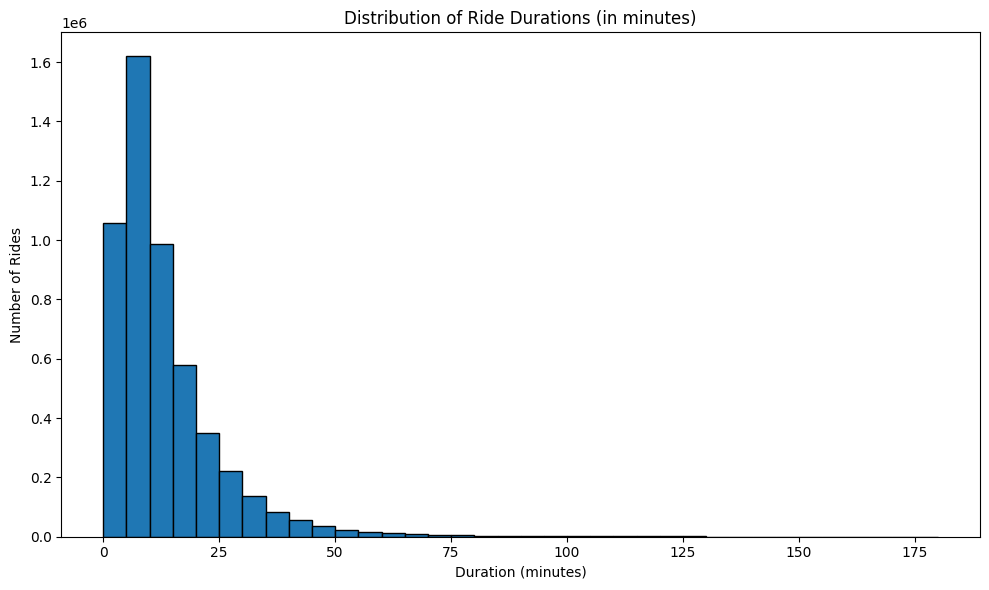

In [124]:
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(figsize=(10, 6))
ax.hist(df_clean['duration_min'], bins=np.arange(0, 181, 5), edgecolor='black')

ax.set_title('Distribution of Ride Durations (in minutes)')
ax.set_xlabel('Duration (minutes)')
ax.set_ylabel('Number of Rides')
plt.tight_layout()
plt.show()

### Q2. Expected duration, variance, and P(duration > 20 min)

In [125]:
# Expected (average) ride duration
avg_duration_min = df_clean['duration_min'].mean()
# Empirical variance of ride duration
empirical_variance = df_clean['duration_min'].var()
# Probability that a ride lasts more than 20 minutes
prob_duration_over_20 = len(df_clean[df_clean['duration_min'] > 20]) / len(df_clean)

print(f"Average ride duration: {avg_duration_min:.2f} minutes")
print(f"Empirical variance of ride duration: {empirical_variance:.2f}")
print(f"Probability of ride lasting more than 20 minutes: {prob_duration_over_20:.2f}")

Average ride duration: 13.41 minutes
Empirical variance of ride duration: 157.22
Probability of ride lasting more than 20 minutes: 0.19


### Q3. P(duration > 20 min | member)

In [126]:
members = df_clean[df_clean['member_casual'] == 'member']
prob_greater_than_20_given_member = (members['duration_min'] > 20).mean()
print(f"Probability of ride lasting more than 20 minutes given the user is a Citi Bike member: {prob_greater_than_20_given_member:.2f}")

Probability of ride lasting more than 20 minutes given the user is a Citi Bike member: 0.15


### Q4. P(member | duration > 25 min)

In [127]:
rides_longer_than_25_min = len(df_clean[df_clean['duration_min'] > 25])  # rides lasting more than 25 minutes
riders_longer_than_25_min_and_member = len(df_clean[(df_clean['duration_min'] > 25) & (df_clean['member_casual'] == 'member')])  # ...that also belong to a member
prob_member_given_long_ride = riders_longer_than_25_min_and_member / rides_longer_than_25_min
print(f"Probability of being a Citi Bike member given the ride lasts more than 25 minutes: {prob_member_given_long_ride:.2f}")

Probability of being a Citi Bike member given the ride lasts more than 25 minutes: 0.60


### Q5. Expected duration by bike type

In [128]:
avg_ride_duration_electric = df_clean[df_clean['rideable_type'] == 'electric_bike']['duration_min'].mean()
avg_ride_duration_classic = df_clean[df_clean['rideable_type'] == 'classic_bike']['duration_min'].mean()
print(f"Expected ride duration of an electric bike: {avg_ride_duration_electric:.2f} minutes")
print(f"Expected ride duration of a classic bike: {avg_ride_duration_classic:.2f} minutes")

Expected ride duration of an electric bike: 13.36 minutes
Expected ride duration of a classic bike: 13.54 minutes


### Q6. P(bike type | duration < 10 min)

In [129]:
prob_electric_given_short_ride = len(df_clean[(df_clean['duration_min'] < 10) & (df_clean['rideable_type'] == 'electric_bike')]) / len(df_clean[df_clean['duration_min'] < 10])
prob_classic_given_short_ride = len(df_clean[(df_clean['duration_min'] < 10) & (df_clean['rideable_type'] == 'classic_bike')]) / len(df_clean[df_clean['duration_min'] < 10])
print(f"Probability of using an electric bike given the ride lasts less than 10 minutes: {prob_electric_given_short_ride:.2f}")
print(f"Probability of using a classic bike given the ride lasts less than 10 minutes: {prob_classic_given_short_ride:.2f}")
print("Comment: The probabilities indicate that for rides lasting less than 10 minutes, there is a higher likelihood of using a classic bike compared to an electric bike. This could suggest that users prefer classic bikes for shorter trips, possibly due to convenience or availability.")

Probability of using an electric bike given the ride lasts less than 10 minutes: 0.72
Probability of using a classic bike given the ride lasts less than 10 minutes: 0.28
Comment: The probabilities indicate that for rides lasting less than 10 minutes, there is a higher likelihood of using a classic bike compared to an electric bike. This could suggest that users prefer classic bikes for shorter trips, possibly due to convenience or availability.


## 3. Part I: Modeling Citi Bike Stations Using Markov Chains

**Goal:** model the number of available bikes at a station as a Markov chain. For example, if a station near Central Park has 20 bikes early on a Monday morning, estimate how many will be available later that morning and understand the station's longer-run behavior.

### Setup
- **Stations:** choose **three popular Citi Bike stations** in NYC with substantial activity, and **explain the selection**.
- **Time blocks:** split the day into **two blocks** (e.g., morning and evening), **weekdays only**. Specify the hours in each block.
- **Time step:** discretize each block into periods of **5 or 10 minutes** (or justify another choice).
- **Model:** the number of available bikes at a station is a **discrete-time Markov chain**.
  - Natural state space: $\{0, 1, \ldots, C\}$, where $C$ is the station's capacity (number of docks, from Google Maps).
  - Estimate transitions from the **arrivals and departures** in each time interval.
  - Estimate a **separate transition model for each station × time block** (3 stations × 2 blocks = 6 models), using the **August weekday** data.

This is open-ended: make and justify your own modeling choices, state assumptions clearly, and explain how the model connects to the data. A different formulation is allowed if you explain why it's appropriate and how it addresses the objective.

### Report requirements
1. **Model definition.** Define the state space, time step, and transition mechanism. Explain how the Markov chain is estimated from the data and how situations not fully specified by the observations are handled.
2. **Transition matrices.** Present the estimated transition matrices (or a concise representation if they're large). Explain how they differ across stations and time blocks.
3. **Stationary distributions.** Compute and interpret them. Discuss whether a stationary distribution exists and is unique for the model; if not, explain why and give an appropriate alternative summary.
4. **Interpretation.** Discuss what the results imply about station activity and bike availability, the long-run behavior of each station, and any limitations of these conclusions.

### Checklist
- [ ] 3 stations chosen, with justification
- [ ] 2 weekday time blocks defined (hours specified)
- [ ] Time step chosen (5 / 10 min, or justified alternative)
- [ ] Station capacities (docks) recorded
- [ ] State space, transition mechanism, and estimation method defined
- [ ] Handling of unobserved / unspecified transitions explained
- [ ] 6 transition matrices estimated and presented
- [ ] Differences across stations and blocks discussed
- [ ] Stationary distributions computed; existence and uniqueness discussed
- [ ] Implications, long-run behavior, and limitations discussed

In [145]:
dfleft_weekday_clean = df_clean[df_clean['started_at'].dt.dayofweek <5].copy()
dfreturned_weekday_clean = df_clean[df_clean["ended_at"].dt.dayofweek <5].copy()

In [147]:
dfreturned_weekday_clean.groupby(['start_station_name', 'end_station_name']).size().sort_values(ascending=False).head(10)

start_station_name          end_station_name          
7 Ave & Central Park South  7 Ave & Central Park South    1329
Central Park S & 6 Ave      Central Park S & 6 Ave        1104
Vernon Blvd & 50 Ave        55 Ave & Center Blvd           716
N 6 St & Bedford Ave        S 2 St & Kent Ave              684
55 Ave & Center Blvd        Vernon Blvd & 50 Ave           627
Roosevelt Island Tramway    Roosevelt Island Tramway       619
Soissons Landing            Soissons Landing               605
N 6 St & Bedford Ave        S 4 St & Wythe Ave             604
S 2 St & Kent Ave           N 6 St & Bedford Ave           577
S 4 St & Wythe Ave          N 6 St & Bedford Ave           565
dtype: int64

## Station 1: 7 Ave & Central Park South

Ultiamte goal is to understand how many bikes are in the dock, at different time

1. 8  Classic                 
2. 16 Ebikes
3. 38 Docks

In [186]:
dfleft_weekday_clean = df_clean[(df_clean['started_at'].dt.dayofweek <5) & (df_clean["started_at"].dt.hour < 12)].copy()
dfreturned_weekday_clean = df_clean[(df_clean["ended_at"].dt.dayofweek <5) & (df_clean["ended_at"].dt.hour < 12)].copy()

StartedAt_Station1 = dfleft_weekday_clean[dfleft_weekday_clean['start_station_name'] == '7 Ave & Central Park South'].copy() # Gets all the Users that rented the bike
EndedAt_Station1 = dfreturned_weekday_clean[dfreturned_weekday_clean['end_station_name'] == '7 Ave & Central Park South'].copy() # Gets all the Users that returned the bike

left_counts = StartedAt_Station1["started_at"].dt.floor("10min").value_counts() # Creates different buckest for 10 min interval in a given day and counts each one that repeats
return_counts = EndedAt_Station1["ended_at"].dt.floor("10min").value_counts()
net_change = return_counts.subtract(left_counts, fill_value=0).sort_index() # Subtarcys returned bikes - rented_bikes, if both dont exists skip, if left or right unknown treat it as zero 
net_change

2026-08-03 00:00:00   -4.0
2026-08-03 00:10:00    0.0
2026-08-03 00:20:00   -1.0
2026-08-03 01:20:00    0.0
2026-08-03 01:30:00   -1.0
                      ... 
2026-08-31 11:10:00   -5.0
2026-08-31 11:20:00    2.0
2026-08-31 11:30:00    0.0
2026-08-31 11:40:00   -4.0
2026-08-31 11:50:00    5.0
Name: count, Length: 952, dtype: float64

A think to note here we ignore when time intervals where nothing happens, but this could be indicative of a silent day, if we add those 0 counts then it will add more 0 to the prob of nothing changing in bikes, i think for now its best to keep our code as is as were trying to find out what happens in worse case everone treats the time the same

In [187]:

net_counts = net_change.value_counts().sort_index()
net_table = net_counts.rename_axis("net_change").reset_index(name="count")
net_table["probability"] = net_table["count"] / net_table["count"].sum()
net_table

,net_change,count,probability
0,-10.0,1,0.001050
1,-9.0,3,0.003151
2,-8.0,2,0.002101
3,-7.0,6,0.006303
4,-6.0,9,0.009454
5,-5.0,19,0.019958
6,-4.0,26,0.027311
7,-3.0,41,0.043067
8,-2.0,75,0.078782
9,-1.0,168,0.176471


### Morning Time Block

### Afternoon Time Block

In [ ]:
afternoon = StartedAt_Station1.loc[(StartedAt_Station1["started_at"].dt.hour >= 12)].copy()

In [ ]:
afternoon.shape

(6719, 14)